In [1]:
#using Pkg
#Pkg.add("https://github.com/WAVI-ice-sheet-model/WAVI.jl"), Pkg.add(Plots); Pkg.add("Downloads")
using WAVI, Downloads, LinearAlgebra, Plots
using Random

BLAS.set_num_threads(1)

# ## Reading in data
# First, let's define our grid sizes and origin. We have a 268 x 315 with, with 3km resolution.
# We're going to use 12 levels in the vertical: even though WAVI.jl is designed for the solution of depth integrated equations, it retains some information about the vertical direction e.g. in the calculation of the ice viscosity; the keyword argument `nσ`, which is passed to a `Grid` object, specifies the number of levels in the vertical. We refer to the extension of the 2D (horizontal) grid to n$\sigma$ levels in the vertical as the 3D grid, which has size nx $\times$ ny $\times$ nz.
nx = 164        #number of x grid points
ny = 192        #number of y grid pointd
nσ = 12         #number of sigma grid points
x0 = -1802500.0 #origin of the grid in x
y0 = -847500.0  #origin of the grid in y
dx = 5000.0     #grid resolution in x
dy = 5000.0     #grid resolution in y

# We're going to read in the following data files:
#   * h_mask     : array of zeros and ones defining the ice domain (zero corresponds to out of domain, one to in domain).
#   * u_iszero   : location of grid points with zero velocity in x
#   * v_iszero   : location of grid points with zero velocity in y
#   * bed        : the bed elevation, which is a processed form of data from Bedmap 2.
#   * h          : ice thickness , defined on the 2D grid
#   * viscosity  : the initial ice viscosity, defined on the 3D grid 

# We need the first three of these before we can build a grid
h_mask=Array{Float64}(undef,nx,ny);
read!(Downloads.download("https://github.com/alextbradley/WAVI_example_data/raw/refs/heads/main/WAIS/Inverse_5km_h_mask_clip_BedmachineV3.bin"),h_mask);
hm = ntoh.(h_mask);
hm = map.(Bool, round.(Int, hm));

u_iszero=Array{Float64}(undef,nx+1,ny);
read!(Downloads.download("https://github.com/alextbradley/WAVI_example_data/raw/refs/heads/main/WAIS/Inverse_5km_uiszero_clip_BedmachineV3.bin"),u_iszero);
u_iszero.=ntoh.(u_iszero);
u_iszero = map.(Bool, round.(Int, u_iszero));

v_iszero=Array{Float64}(undef,nx,ny+1);
read!(Downloads.download("https://github.com/alextbradley/WAVI_example_data/raw/refs/heads/main/WAIS/Inverse_5km_uiszero_clip_BedmachineV3.bin"),v_iszero);
v_iszero.=ntoh.(v_iszero);
v_iszero = map.(Bool, round.(Int, v_iszero));

grid = Grid(nx = nx, ny = ny, nσ = nσ, x0 = x0, y0 = y0, dx = dx, dy = dy, h_mask = hm, u_iszero = u_iszero, v_iszero = v_iszero);


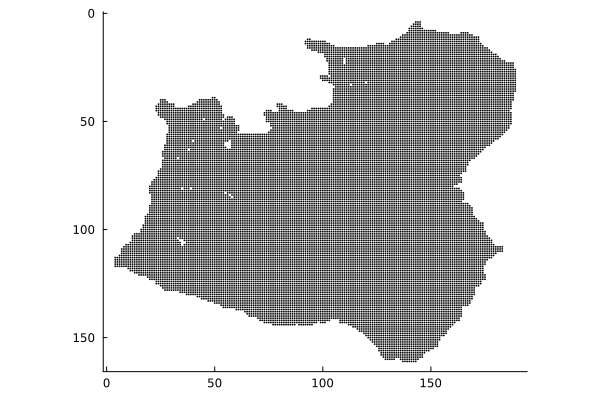

In [2]:
# Before moving on to the rest, let's have a look at h_mask using the `spy` function, which indicates which entries of a matrix are non-zero:
Plots.spy(hm)
# We see a rough outline of West Antarctica! This is out ice domain. Note that indices with h_mask[i,j] = 0 are simply placeholders and do not have any physical meaning.


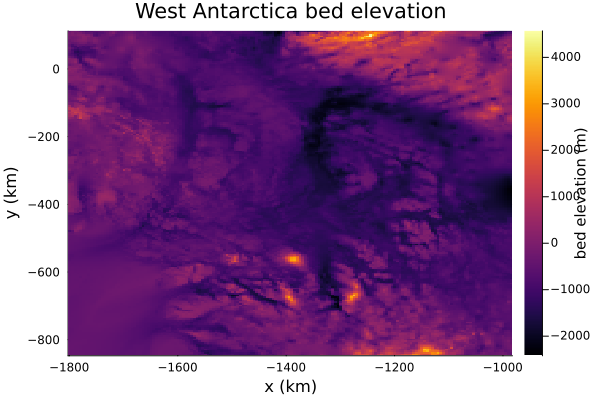

In [29]:
# Next up: the bed, which will be passed to a model via the `bed_elevation` keyword article, as usual.
bed=Array{Float64}(undef,nx,ny);
read!(Downloads.download("https://github.com/alextbradley/WAVI_example_data/raw/refs/heads/main/WAIS/Inverse_5km_bed_clip_noNan_BedmachineV3.bin"),bed);
bed.=ntoh.(bed);

# Let's take a look at the bed
plt = Plots.heatmap(grid.xxh[:,1]/1e3, grid.yyh[1,:]/1e3, bed', 
                    xlabel = "x (km)", 
                    ylabel = "y (km)",
                    colorbar_title = "bed elevation (m)",
                    title = "West Antarctica bed elevation",
                    framestyle = "box")



In [30]:
# Temperature, damage, viscosity, and thickness will be passed to a model via initial conditions (these quantities are time dependent)
temp=Array{Float64}(undef,nx,ny,nσ);
read!(Downloads.download("https://github.com/alextbradley/WAVI_example_data/raw/refs/heads/main/WAIS/Inverse_5km_3Dtemp_clip_noNan_BedmachineV3.bin"),temp);
temp.=ntoh.(temp);

damage=Array{Float64}(undef,nx,ny,nσ);
read!(Downloads.download("https://github.com/alextbradley/WAVI_example_data/raw/refs/heads/main/WAIS/Inverse_5km_damage3D_clip_noNan_BedmachineV3.bin"),damage);
damage.=ntoh.(damage);

h=Array{Float64}(undef,nx,ny);
read!(Downloads.download("https://github.com/alextbradley/WAVI_example_data/raw/refs/heads/main/WAIS/Inverse_5km_thickness_clip_noNan_BedmachineV3.bin"),h);
h.=ntoh.(h);

viscosity=Array{Float64}(undef,nx,ny,nσ);
read!(Downloads.download("https://github.com/alextbradley/WAVI_example_data/raw/refs/heads/main/WAIS/Inverse_5km_viscosity3D_clip_noNan_BedmachineV3.bin"),viscosity);
viscosity.=ntoh.(viscosity);

solver_params=SolverParams(maxiter_picard=20)

initial_conditions = InitialConditions(initial_thickness = h,initial_viscosity = viscosity,initial_temperature = temp,initial_damage = damage);

parallel_spec = BasicParallelSpec()


BasicParallelSpec()

In [31]:
# ## Ice Velocity
# Now we're ready to make our model, which we can then use to determine the ice velocity. All physical and solver parameters take their default values
serial_model = Model(grid = grid, bed_elevation = bed,initial_conditions= initial_conditions, parallel_spec = parallel_spec, solver_params=solver_params);

# We use the `update_state!` method to bring fields (including velocity) in line with the ice thickness:
update_state!(serial_model)

Solved momentum equation on thread 1 with residual 0.000661 at iteration 20


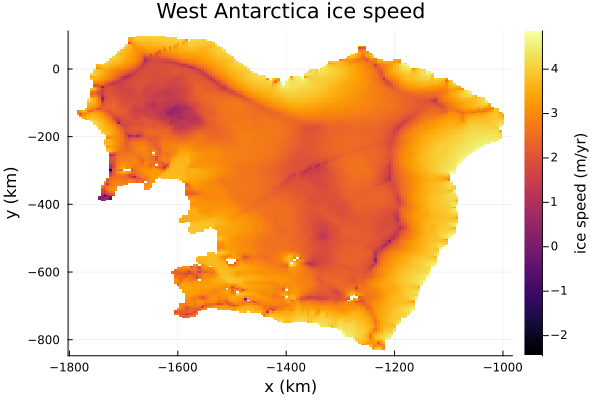

In [32]:
# Now we can visualize the ice velocity:plt = Plots.heatmap(grid.xxh[:,1]/1e3, grid.yyh[1,:]/1e3, log10.(serial_model.fields.gh.av_speed'), 
plt = Plots.heatmap(grid.xxh[:,1]/1e3, grid.yyh[1,:]/1e3, 
log10.(serial_model.fields.gh.av_speed'), 
                    xlabel = "x (km)", 
                    ylabel = "y (km)",
                    colorbar_title = "ice speed (m/yr)",
                    title = "West Antarctica ice speed",
             #       clims=(-0.02,0.02),
             #       xlims=(-1400,-1300),
             #       ylims=(-500,-400),
                    framestyle = "box")


In [33]:
# Now try the same velocity solve with a shared memory parallel implementation                     
saved_serial_model=deepcopy(serial_model);

parallel_model = deepcopy(serial_model)
parallel_model = @set parallel_model.solver_params = SolverParams(maxiter_picard=5)
parallel_model = @set parallel_model.parallel_spec = SharedMemorySpec(ngridsx=2,ngridsy=3,overlap=1,damping=0.0,niterations=1)


Model{Float64, Int64, Matrix{Float64}, Matrix{Float64}, Matrix{Float64}, UniformMeltRate{Float64}, ConstantDamage, SharedMemorySpec{Float64, Int64}}(Grid{Float64, Int64}(164, 192, 12, 5000.0, 5000.0, -1.8025e6, -847500.0, Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], [-1.8e6 -1.8e6 … -1.8e6 -1.8e6; -1.795e6 -1.795e6 … -1.795e6 -1.795e6; … ; -990000.0 -990000.0 … -990000.0 -990000.0; -985000.0 -985000.0 … -985000.0 -985000.0], [-845000.0 -840000.0 … 105000.0 110000.0; -845000.0 -840000.0 … 105000.0 110000.0; … ; -845000.0 -840000.0 … 105000.0 110000.0; -845000.0 -840000.0 … 105000.0 110000.0], [-1.8025e6 -1.8025e6 … -1.8025e6 -1.8025e6; -1.7975e6 -1.7975e6 … -1.7975e6 -1.7975e6; … ; -987500.0 -987500.0 … -987500.0


Solved momentum equation on thread 2 with residual 0.00633 at iteration 5
Solved momentum equation on thread 2 with residual 0.00328 at iteration 5
Solved momentum equation on thread 2 with residual 0.000931 at iteration 5
Solved momentum equation on thread 2 with residual 0.000321 at iteration 5
Solved momentum equation on thread 2 with residual 7.94e-5 at iteration 5
Solved momentum equation on thread 2 with residual 6.34e-5 at iteration 5


Solved momentum equation on thread 2 with residual 0.00148 at iteration 5
Solved momentum equation on thread 2 with residual 5.04e-5 at iteration 5
Solved momentum equation on thread 2 with residual 0.000153 at iteration 5
Solved momentum equation on thread 2 with residual 0.000964 at iteration 5
Solved momentum equation on thread 2 with residual 1.93e-5 at iteration 5
Solved momentum equation on thread 2 with residual 1.99e-5 at iteration 5


Solved momentum equation on thread 2 with residual 0.000519 at iteration 5
Solved momentum equation on 

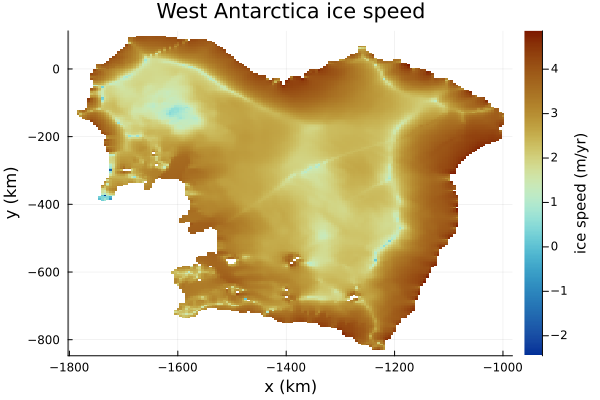

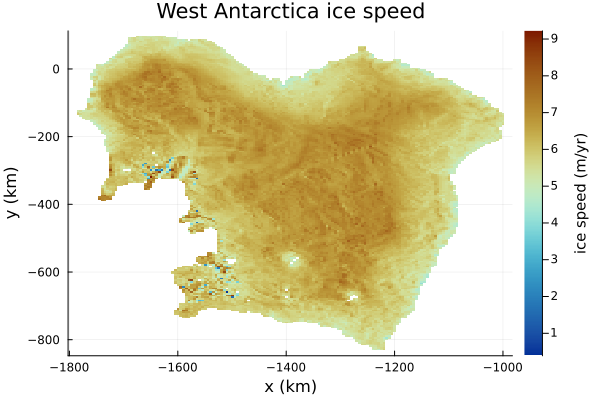

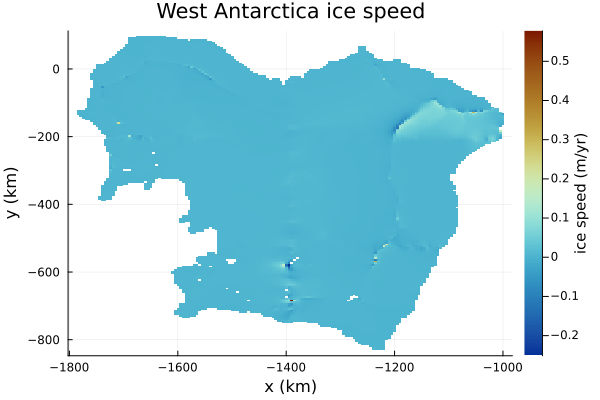

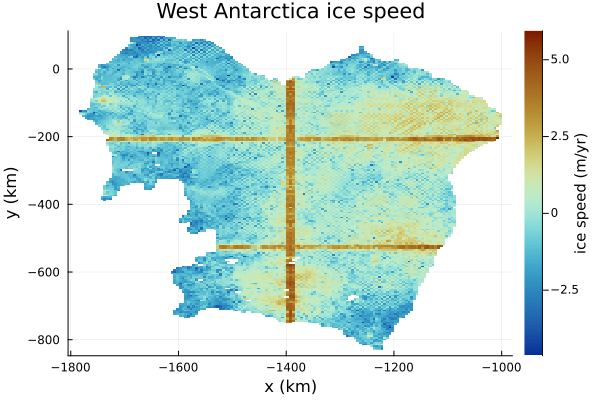

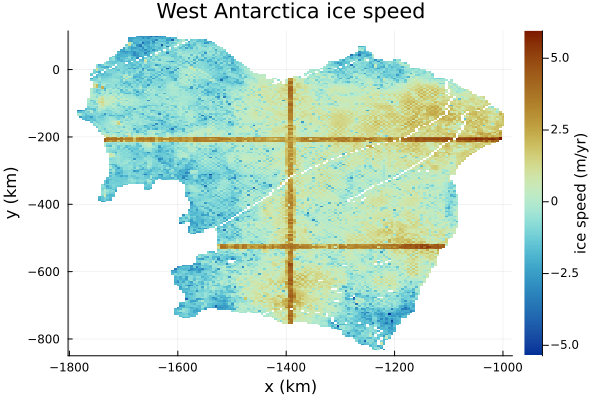

In [34]:
cols=cgrad(:roma,rev=true);
nSchwarzIterations=1
for iSchwarzIteration = 1:nSchwarzIterations
       update_state!(parallel_model)


       # Now we can visualize the ice velocity:
       plt = Plots.heatmap(grid.xxh[:,1]/1e3, grid.yyh[1,:]/1e3, 
       log10.(parallel_model.fields.gh.av_speed'), 
                     c = cols, 
                     xlabel = "x (km)", 
                     ylabel = "y (km)",
                     colorbar_title = "ice speed (m/yr)",
                     title = "West Antarctica ice speed",
              #       clims=(-0.2,0.2),
              #       xlims=(-1600,-1500),
              #       ylims=(-700,-600),
                     framestyle = "box")
       display(plt)

       plt = Plots.heatmap(grid.xxh[:,1]/1e3, grid.yyh[1,:]/1e3, log10.(parallel_model.fields.gh.ηav'), 
       c = cols,
       xlabel = "x (km)", 
       ylabel = "y (km)",
       colorbar_title = "ice speed (m/yr)",
       title = "West Antarctica ice speed",
#       clims=(-0.2,0.2),
#       xlims=(-1600,-1500),
#       ylims=(-700,-600),
       framestyle = "box")
       display(plt)

       plt = Plots.heatmap(grid.xxh[:,1]/1e3, grid.yyh[1,:]/1e3, log10.(parallel_model.fields.gh.av_speed'./serial_model.fields.gh.av_speed'), 
       c = cols,
       xlabel = "x (km)", 
       ylabel = "y (km)",
       colorbar_title = "ice speed (m/yr)",
       title = "West Antarctica ice speed",
#       clims=(-0.2,0.2),
#       xlims=(-1600,-1500),
#       ylims=(-700,-600),
       framestyle = "box")
       display(plt)

# Ice velocities reach a maximum of approx 5km/yr on ice shelves, but are much smaller inland.

       plt = Plots.heatmap(grid.xxu[:,1]/1e3, grid.yyu[1,:]/1e3, log10.(abs.(parallel_model.fields.gu.residual')), 
                     c = cols,
                     xlabel = "x (km)", 
                     ylabel = "y (km)",
                     colorbar_title = "ice speed (m/yr)",
                     title = "West Antarctica ice speed",
              #       clims=(-0.02,0.02),
              #       xlims=(-1400,-1300),
              #       ylims=(-500,-400),
                     framestyle = "box")
       display(plt)

       plt = Plots.heatmap(grid.xxv[:,1]/1e3, grid.yyv[1,:]/1e3, log10.(abs.(parallel_model.fields.gv.residual')), 
                     c=cols,
                     xlabel = "x (km)", 
                     ylabel = "y (km)",
                     colorbar_title = "ice speed (m/yr)",
                     title = "West Antarctica ice speed",
              #       clims=(-0.02,0.02),
              #       xlims=(-1400,-1300),
              #       ylims=(-500,-400),
                     framestyle = "box")
       display(plt)

 end

In [37]:
Φ = parallel_model.fields.g3d.Φ


164×192×12 Array{Float64, 3}:
[:, :, 1] =
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 ⋮                        ⋮              ⋱  ⋮                        ⋮    
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0 

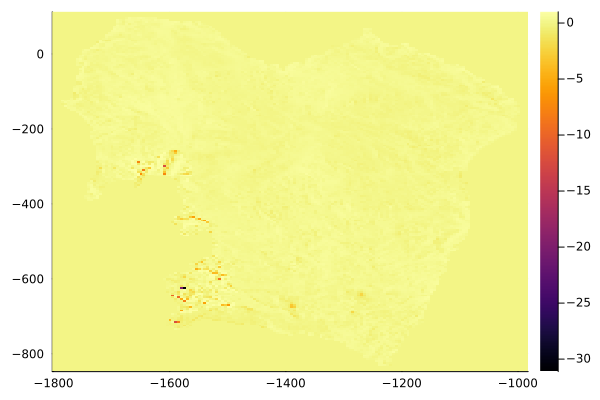

In [52]:
heatmap(grid.xxh[:,1]/1e3, grid.yyh[1,:]/1e3,
Φ[:,:,5]')

In [41]:
ti = 1

plt = Plots.heatmap(grid.xxv[:,1]/1e3, grid.yyv[1,:]/1e3,
Φ[:,:,ti]', 
                c=cols,
                xlabel = "x (km)", 
                ylabel = "y (km)",
                colorbar_title = "phase field",
                title = "West Antarctica ice speed",
        #       clims=(-0.02,0.02),
        #       xlims=(-1400,-1300),
        #       ylims=(-500,-400),
                framestyle = "box")
display(plt)

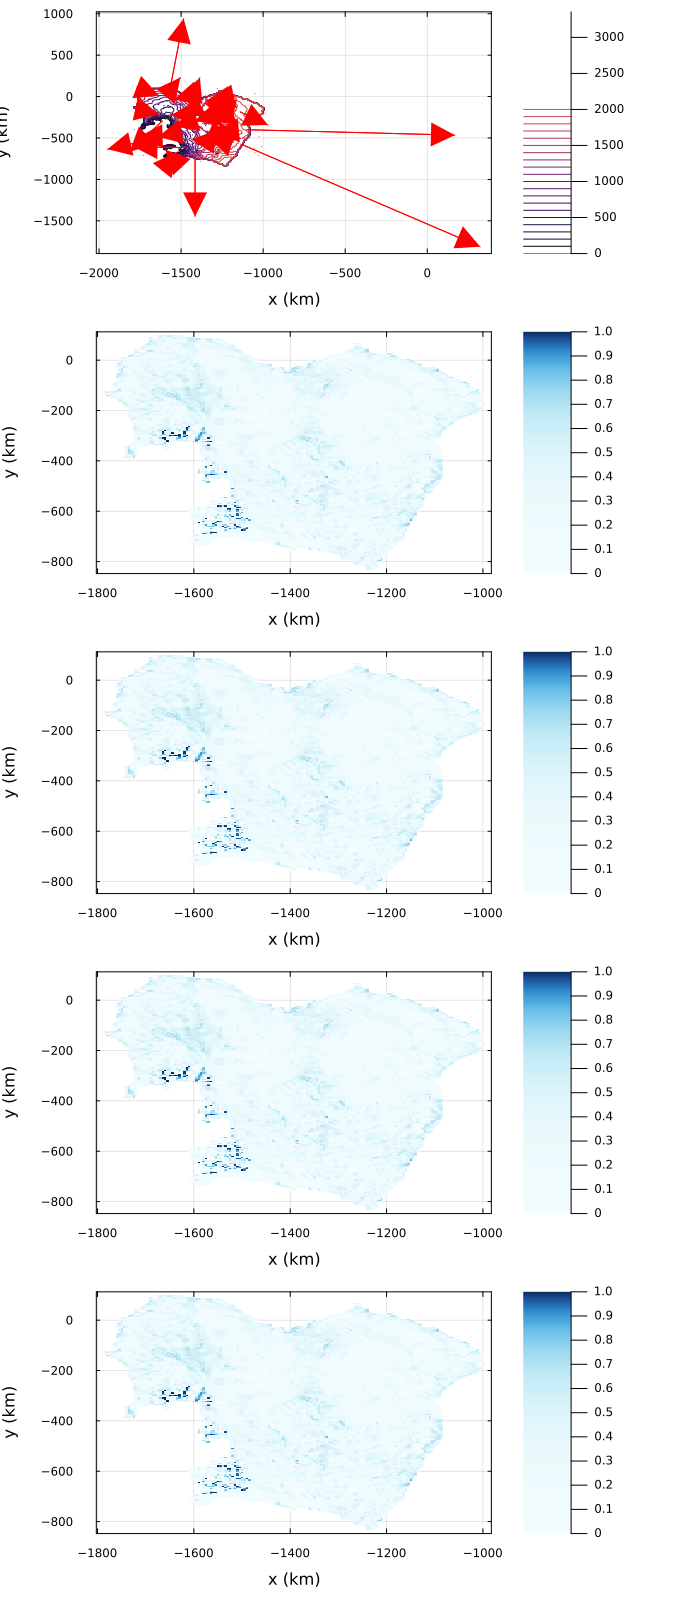

In [77]:
xx= parallel_model.grid.xxh/1000
yy = parallel_model.grid.yyh/1000
s = parallel_model.fields.gh.s
u = parallel_model.fields.gh.u
v = parallel_model.fields.gh.v
Φ = parallel_model.fields.g3d.Φ

Φ1 = copy(Φ[:,:,1])
Φ1[.!hm] .= NaN

arrow_length = 100/1000
n_arrows = 50
ss = randperm(length(xx))[1:n_arrows]
clim = (0,1.0)
cmap = colormap("Blues", logscale = true)
p1=heatmap(xx[:,1],yy[1,:],(Φ1[:,:,1]./hm)',clim = clim,xlabel="x (km)",ylabel="y (km)", colormap = cmap, framestyle = :box)
p2=heatmap(xx[:,1],yy[1,:],(Φ[:,:,2]./hm)',clim = clim,xlabel="x (km)",ylabel="y (km)", colormap = cmap, framestyle = :box)
p3=heatmap(xx[:,1],yy[1,:],(Φ[:,:,3]./hm)',clim = clim,xlabel="x (km)",ylabel="y (km)", colormap = cmap, framestyle = :box)
p4=heatmap(xx[:,1],yy[1,:],(Φ[:,:,4]./hm)',clim = clim,xlabel="x (km)",ylabel="y (km)", colormap = cmap, framestyle = :box)
p5=contour(xx[:,1],yy[1,:],s', levels = 0:100:2000,xlabel="x (km)",ylabel="y (km)", framestyle = :box)
p5 = quiver!(p5,xx[ss],yy[ss],quiver=(arrow_length*u[ss], arrow_length*v[ss]), color = :red, arrow = Plots.arrow(:closed, :head, 0.01, 0.01))
plot(p5,p4,p3,p2,p1;layout=(5,1),size=(700,1600),left_margin=10Plots.mm,right_margin=10Plots.mm)
